# Bank Marketing: Data-Quality Assessment and Cleaning

**Author:** Joy Bello
**Dataset:** UCI Bank Marketing (`bank-additional-full.csv`): 41,188 telemarketing calls made by a Portuguese bank, May 2008 to November 2010
**Decision this supports:** *Who should the bank call, and how often, in its next term-deposit telemarketing campaign?*

This notebook:
1. **Profiles** the raw data (structure, missing values, hidden missing values, duplicates, ranges, sentinel codes, logical consistency).
2. Records every issue in an **issues log** with the decision taken and why.
3. **Cleans** the data in one reusable function.
4. **Validates** the cleaned output with explicit checks.
5. Runs a short **decision-oriented analysis** on the cleaned data (feeds the one-page decision brief).
6. **Exports** the cleaned dataset, quality reports and figures.

Assumptions and limitations are listed at the end.

## 1. Setup and configuration

In [1]:
from pathlib import Path
from io import BytesIO
from urllib.request import urlopen
from zipfile import ZipFile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid", context="notebook")

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

CONFIG = {
    "raw_file": ROOT / "data/raw/bank-additional-full.csv",
    "clean_file": ROOT / "data/processed/bank_marketing_clean.csv",
    "output_dir": ROOT / "outputs",
    "figure_dir": ROOT / "outputs/figures",
    "official_url": "https://archive.ics.uci.edu/static/public/222/bank+marketing.zip",
    "target": "y",
    "positive_label": "yes",
    "pdays_sentinel": 999,          # UCI code for 'not previously contacted'
    "high_contact_threshold": 10,   # campaign calls above this are flagged
    "min_group_size": 100,          # smallest segment reported in the analysis
}
for d in (CONFIG["output_dir"], CONFIG["figure_dir"], CONFIG["clean_file"].parent):
    d.mkdir(parents=True, exist_ok=True)

EXPECTED_COLUMNS = [
    "age", "job", "marital", "education", "default", "housing", "loan",
    "contact", "month", "day_of_week", "duration", "campaign", "pdays",
    "previous", "poutcome", "emp.var.rate", "cons.price.idx",
    "cons.conf.idx", "euribor3m", "nr.employed", "y",
]
print("Project root:", ROOT)

Project root: /home/claude/repo


## 2. Load the raw data
Uses the local copy if present, otherwise downloads the official UCI archive. The raw file is never modified.

In [2]:
def load_raw(config: dict) -> pd.DataFrame:
    path = config["raw_file"]
    if not path.exists():
        print("Local file not found - downloading from UCI ...")
        with urlopen(config["official_url"], timeout=60) as resp:
            outer = ZipFile(BytesIO(resp.read()))
        inner = ZipFile(BytesIO(outer.read("bank-additional.zip")))
        path.parent.mkdir(parents=True, exist_ok=True)
        path.write_bytes(inner.read("bank-additional/bank-additional-full.csv"))
    frame = pd.read_csv(path, sep=";")
    print(f"Loaded {frame.shape[0]:,} rows x {frame.shape[1]} columns from {path.name}")
    return frame

raw = load_raw(CONFIG)
raw.head()

Loaded 41,188 rows x 21 columns from bank-additional-full.csv


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,261,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,149,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,226,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,151,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,307,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


## 3. Data-quality profiling
### 3.1 Schema check

In [3]:
missing_cols = sorted(set(EXPECTED_COLUMNS) - set(raw.columns))
extra_cols = sorted(set(raw.columns) - set(EXPECTED_COLUMNS))
assert not missing_cols, f"Missing columns: {missing_cols}"
print("All 21 expected columns present. Unexpected columns:", extra_cols or "none")
print("Target values:", raw[CONFIG["target"]].value_counts().to_dict())

All 21 expected columns present. Unexpected columns: none
Target values: {'no': 36548, 'yes': 4640}


### 3.2 Missing values, including hidden missing values

The file has **no empty cells**, but that is misleading: missing information is coded as the text `"unknown"` in six categorical columns.

> **Note on the Week 3 notebook:** its quality report showed `unknown_count = 0` for every column. That check only ran when `dtype == "object"`, but pandas 3 stores text as the `str` dtype, so the check was silently skipped. The version below tests for *any non-numeric* column and reports the real counts.

In [4]:
def quality_profile(frame: pd.DataFrame) -> pd.DataFrame:
    text_cols = frame.select_dtypes(exclude="number").columns
    report = pd.DataFrame({
        "dtype": frame.dtypes.astype(str),
        "null_count": frame.isna().sum(),
        "unknown_count": [int((frame[c] == "unknown").sum()) if c in text_cols else 0
                          for c in frame.columns],
        "unique_values": frame.nunique(dropna=False),
    })
    report["unknown_pct"] = (100 * report["unknown_count"] / len(frame)).round(2)
    report.index.name = "column"
    return report.sort_values("unknown_count", ascending=False)

raw_profile = quality_profile(raw)
raw_profile

,dtype,null_count,unknown_count,unique_values,unknown_pct
column,,,,,
default,str,0,8597,3,20.87
education,str,0,1731,8,4.20
housing,str,0,990,3,2.40
loan,str,0,990,3,2.40
job,str,0,330,12,0.80
marital,str,0,80,4,0.19
age,int64,0,0,78,0.00
contact,str,0,0,2,0.00
month,str,0,0,10,0.00


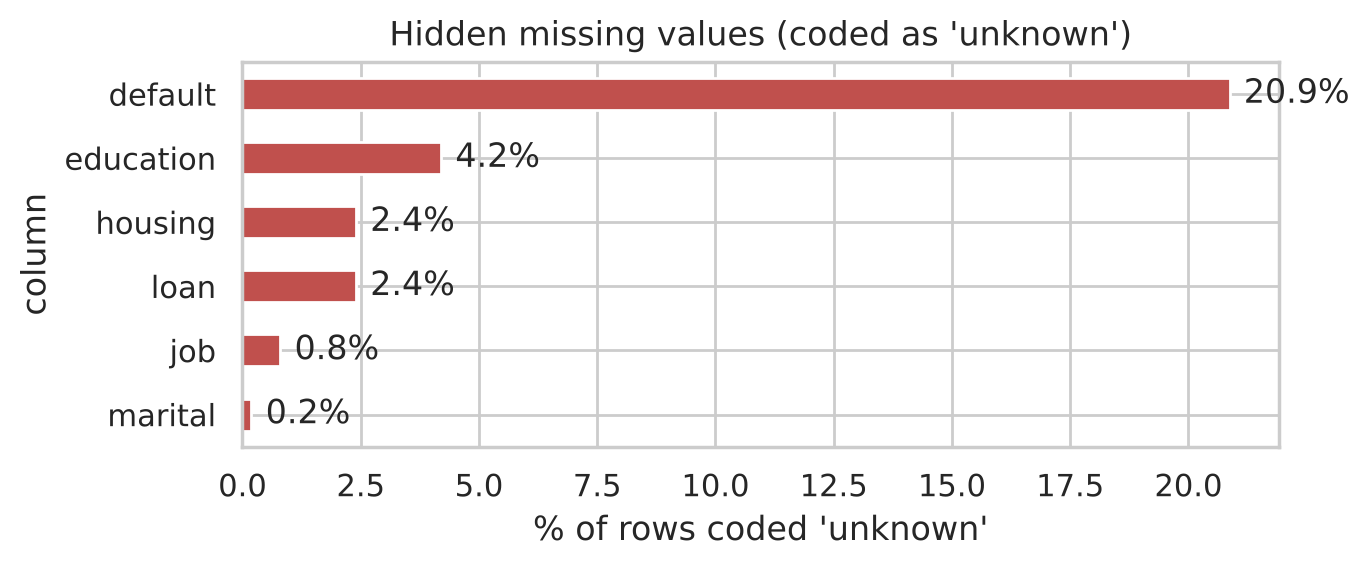

In [5]:
unk = raw_profile.query("unknown_count > 0")["unknown_pct"].sort_values()
ax = unk.plot.barh(color="#c0504d", figsize=(7, 3))
ax.set_xlabel("% of rows coded 'unknown'")
ax.set_title("Hidden missing values (coded as 'unknown')")
for i, v in enumerate(unk):
    ax.text(v + 0.3, i, f"{v:.1f}%", va="center")
plt.tight_layout(); plt.savefig(CONFIG["figure_dir"] / "01_unknown_values.png", dpi=150); plt.show()

### 3.3 Duplicate rows

In [6]:
dup_mask = raw.duplicated(keep=False)
print("Exact duplicate rows (extra copies):", int(raw.duplicated().sum()))
raw[dup_mask].sort_values(list(raw.columns)).head(6)

Exact duplicate rows (extra copies): 12


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
28476,24,services,single,high.school,no,yes,no,cellular,apr,tue,114,1,999,0,nonexistent,-1.8,93.075,-47.1,1.423,5099.1,no
28477,24,services,single,high.school,no,yes,no,cellular,apr,tue,114,1,999,0,nonexistent,-1.8,93.075,-47.1,1.423,5099.1,no
14155,27,technician,single,professional.course,no,no,no,cellular,jul,mon,331,2,999,0,nonexistent,1.4,93.918,-42.7,4.962,5228.1,no
14234,27,technician,single,professional.course,no,no,no,cellular,jul,mon,331,2,999,0,nonexistent,1.4,93.918,-42.7,4.962,5228.1,no
18464,32,technician,single,professional.course,no,yes,no,cellular,jul,thu,128,1,999,0,nonexistent,1.4,93.918,-42.7,4.968,5228.1,no
18465,32,technician,single,professional.course,no,yes,no,cellular,jul,thu,128,1,999,0,nonexistent,1.4,93.918,-42.7,4.968,5228.1,no


There is no customer ID, so we can't tell whether these are double entries or two different customers with identical answers. With 21 attributes matching, including the exact call duration in seconds and the macroeconomic values, double entry is far more likely.

### 3.4 Numeric ranges and sentinel values

In [7]:
raw.describe().T[["min", "25%", "50%", "75%", "max"]]

,min,25%,50%,75%,max
age,17.000,32.000,38.000,47.000,98.000
duration,0.000,102.000,180.000,319.000,4918.000
campaign,1.000,1.000,2.000,3.000,56.000
pdays,0.000,999.000,999.000,999.000,999.000
previous,0.000,0.000,0.000,0.000,7.000
emp.var.rate,-3.400,-1.800,1.100,1.400,1.400
cons.price.idx,92.201,93.075,93.749,93.994,94.767
cons.conf.idx,-50.800,-42.700,-41.800,-36.400,-26.900
euribor3m,0.634,1.344,4.857,4.961,5.045
nr.employed,4963.600,5099.100,5191.000,5228.100,5228.100


In [8]:
s = CONFIG["pdays_sentinel"]
print(f"pdays == {s} (sentinel 'never contacted'): {(raw.pdays == s).sum():,} rows "
      f"({(raw.pdays == s).mean():.1%})")
print("Real pdays values range:", raw.loc[raw.pdays != s, "pdays"].agg(["min", "max"]).tolist())
print("duration == 0 seconds:", int((raw.duration == 0).sum()), "rows -> y =",
      raw.loc[raw.duration == 0, "y"].value_counts().to_dict())
print(f"campaign > {CONFIG['high_contact_threshold']} calls: {(raw.campaign > CONFIG['high_contact_threshold']).sum():,} rows; max = {raw.campaign.max()}")

pdays == 999 (sentinel 'never contacted'): 39,673 rows (96.3%)
Real pdays values range: [0, 27]
duration == 0 seconds: 4 rows -> y = {'no': 4}
campaign > 10 calls: 869 rows; max = 56


`pdays = 999` is a code meaning *not previously contacted*, not a real number of days. Leaving it as a number would distort any mean, correlation or model (the average would be about 960 days).

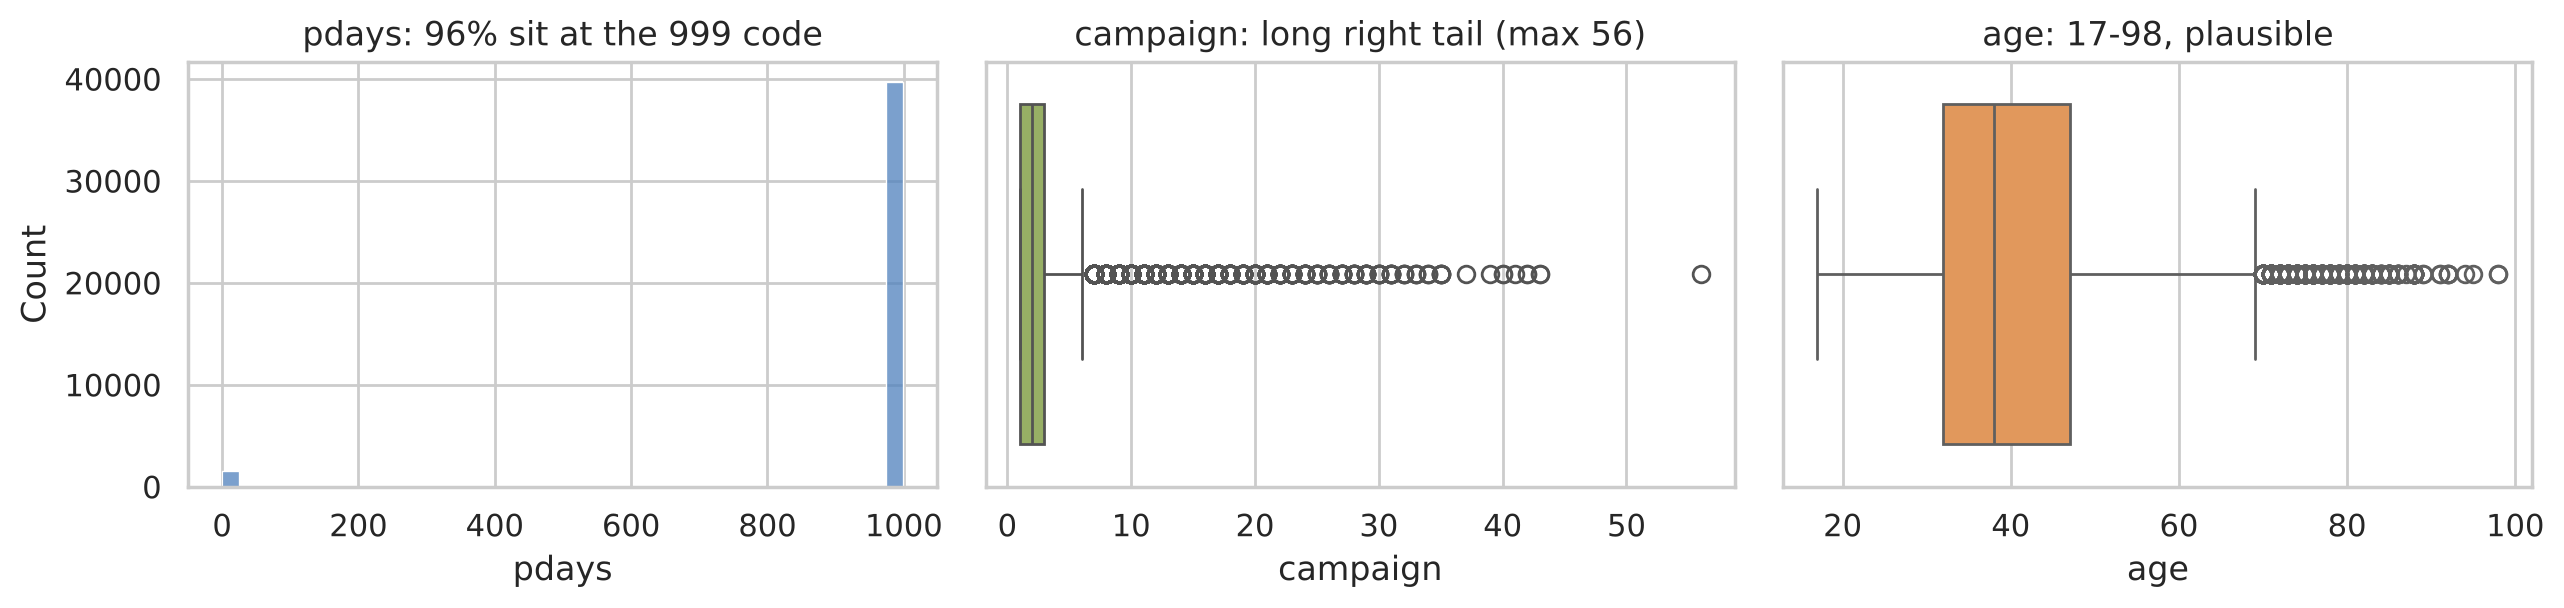

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.2))
sns.histplot(raw.pdays, bins=40, ax=axes[0], color="#4f81bd"); axes[0].set_title("pdays: 96% sit at the 999 code")
sns.boxplot(x=raw.campaign, ax=axes[1], color="#9bbb59"); axes[1].set_title("campaign: long right tail (max 56)")
sns.boxplot(x=raw.age, ax=axes[2], color="#f79646"); axes[2].set_title("age: 17-98, plausible")
plt.tight_layout(); plt.savefig(CONFIG["figure_dir"] / "02_ranges_and_sentinels.png", dpi=150); plt.show()

### 3.5 Logical consistency between related columns
`pdays`, `previous` and `poutcome` all describe contact from a *previous* campaign, so they should agree.

In [10]:
consistency = pd.crosstab(
    [raw.pdays.eq(s).map({True: "pdays=999", False: "pdays real"}),
     raw.previous.gt(0).map({True: "previous>0", False: "previous=0"})],
    raw.poutcome,
)
consistency

poutcome               failure  nonexistent  success
pdays      previous                                 
pdays real previous>0      142            0     1373
pdays=999  previous=0        0        35563        0
           previous>0     4110            0        0

In [11]:
conflict = raw.pdays.eq(s) & raw.previous.gt(0)
print(f"Rows where pdays says 'never contacted' but previous > 0: {conflict.sum():,} "
      f"(all have poutcome = {raw.loc[conflict, 'poutcome'].unique().tolist()})")

Rows where pdays says 'never contacted' but previous > 0: 4,110 (all have poutcome = ['failure'])


About 4,100 customers were contacted in a previous campaign (`previous > 0`, outcome *failure*) but have `pdays = 999`. So `pdays = 999` can't be read as *never contacted*. **`previous` is the reliable indicator** of prior contact, and `pdays` only says how many days ago, when that's known.

### 3.6 Target leakage check

UCI notes that `duration` (call length) is only known **after** the call ends, and that it strongly drives the outcome (a 0-second call is always a *no*). The bank can't know it when choosing whom to call, so it must **not** be used for targeting decisions or predictive models. It is kept in the cleaned file for descriptive use only, and labelled as leakage in the data dictionary.

In [12]:
print(raw.groupby("y").duration.median().rename("median call duration (s)"))

y
no     163.5
yes    449.0
Name: median call duration (s), dtype: float64


### 3.7 Other observations

In [13]:
print("credit default values:", raw["default"].value_counts().to_dict())
print("Months present:", sorted(raw.month.unique()), "(no 'jan' or 'feb' calls)")
print("Year is not recorded; UCI states rows are ordered by date, May 2008 to Nov 2010.")

credit default values: {'no': 32588, 'unknown': 8597, 'yes': 3}
Months present: ['apr', 'aug', 'dec', 'jul', 'jun', 'mar', 'may', 'nov', 'oct', 'sep'] (no 'jan' or 'feb' calls)
Year is not recorded; UCI states rows are ordered by date, May 2008 to Nov 2010.


## 4. Issues log

| # | Issue | Evidence | Rows affected | Decision | Rationale |
|---|---|---|---|---|---|
| 1 | Exact duplicate rows | `duplicated()` | 12 | **Drop** extra copies | Identical across all 21 fields including call seconds; double entry is most likely |
| 2 | Hidden missing values coded `"unknown"` | 6 categorical columns | default 20.9%, education 4.2%, housing/loan 2.4%, job 0.8%, marital 0.2% | **Keep as an explicit `unknown` category**, don't impute or drop | Dropping would remove ~26% of rows. Imputing invents data. "unknown" may itself be informative (e.g. customers who withhold default status) |
| 3 | Week 3 profile undercounted `unknown` | dtype check skipped `str` columns | all | **Fixed** the profiling function | Correct quality reporting |
| 4 | `pdays = 999` sentinel | 96.3% of rows | 39,673 | **Replace with null** in `days_since_prev_contact`; drop raw `pdays` | A code is not a quantity |
| 5 | `pdays` contradicts `previous` | 999 but previous > 0 | 4,110 | **Derive `previously_contacted` from `previous > 0`** | `previous` is internally consistent with `poutcome` |
| 6 | `duration` is target leakage | Known only after call; 0 s means always "no" | all | **Keep, flag in dictionary, exclude from decision analysis** | Prevents an unrealistically optimistic model or targeting rule |
| 7 | `duration = 0` | 0-second calls | 4 | **Keep** | Genuine failed connections, consistent with y = no |
| 8 | Extreme `campaign` values (up to 56 calls) | long right tail | 869 rows > 10 | **Keep, add `high_contact_flag`** | Plausible operational records, not errors, and important for the decision on call caps |
| 9 | `default` almost constant | only 3 "yes" | 3 | **Keep, note low value** | Provides little information beyond yes/unknown |
| 10 | Column names with dots, `default` is an SQL keyword | `emp.var.rate`, `default` | n/a | **Rename** to snake_case, `default` to `credit_default` | Safe use in SQL/BI tools |
| 11 | Text target | `y` = yes/no | all | **Add numeric `subscribed` (1/0)** | Rates and models need numeric target |
| 12 | No year / ordered month | month only | all | **Add `month_num`** for ordering, document missing year | Time trends can't be separated by year |

## 5. Cleaning pipeline
One function that you can re-run: raw in, clean out. The raw dataframe is never changed in place.

In [14]:
MONTH_ORDER = ["jan", "feb", "mar", "apr", "may", "jun", "jul", "aug", "sep", "oct", "nov", "dec"]
DAY_ORDER = ["mon", "tue", "wed", "thu", "fri"]
RENAME = {
    "default": "credit_default",
    "emp.var.rate": "emp_var_rate",
    "cons.price.idx": "cons_price_idx",
    "cons.conf.idx": "cons_conf_idx",
    "nr.employed": "nr_employed",
}

def clean_bank_data(raw_frame: pd.DataFrame, config: dict = CONFIG) -> pd.DataFrame:
    df = raw_frame.copy()

    # 1. Remove exact duplicates
    df = df.drop_duplicates().reset_index(drop=True)

    # 2. Standardise column names
    df = df.rename(columns=RENAME)

    # 3. Tidy text values (trim / lower-case); 'unknown' kept as its own category
    for col in df.select_dtypes(exclude="number").columns:
        df[col] = df[col].str.strip().str.lower()

    # 4. Prior-contact fields: sentinel -> null, reliable flag from `previous`
    df["days_since_prev_contact"] = df["pdays"].where(df["pdays"] != config["pdays_sentinel"])
    df["days_since_prev_contact"] = df["days_since_prev_contact"].astype("Int64")
    df["previously_contacted"] = (df["previous"] > 0).astype(int)
    df = df.drop(columns="pdays")

    # 5. Outlier flag (values kept)
    df["high_contact_flag"] = (df["campaign"] > config["high_contact_threshold"]).astype(int)

    # 6. Helpful derived fields
    df["age_band"] = pd.cut(df["age"], bins=[0, 29, 39, 49, 59, 200],
                            labels=["under_30", "30_39", "40_49", "50_59", "60_plus"]).astype(str)
    df["month_num"] = df["month"].map({m: i + 1 for i, m in enumerate(MONTH_ORDER)}).astype(int)

    # 7. Numeric target
    df["subscribed"] = (df[config["target"]] == config["positive_label"]).astype(int)

    # 8. Logical column order
    order = ["age", "age_band", "job", "marital", "education", "credit_default", "housing", "loan",
             "contact", "month", "month_num", "day_of_week", "duration", "campaign", "high_contact_flag",
             "previous", "previously_contacted", "days_since_prev_contact", "poutcome",
             "emp_var_rate", "cons_price_idx", "cons_conf_idx", "euribor3m", "nr_employed",
             "y", "subscribed"]
    return df[order]

clean = clean_bank_data(raw)
print(f"Raw: {raw.shape}  ->  Clean: {clean.shape}")
clean.head()

Raw: (41188, 21)  ->  Clean: (41176, 26)


,age,age_band,job,marital,education,credit_default,housing,loan,contact,month,month_num,day_of_week,duration,campaign,high_contact_flag,previous,previously_contacted,days_since_prev_contact,poutcome,emp_var_rate,cons_price_idx,cons_conf_idx,euribor3m,nr_employed,y,subscribed
0,56,50_59,housemaid,married,basic.4y,no,no,no,telephone,may,5,mon,261,1,0,0,0,<NA>,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no,0
1,57,50_59,services,married,high.school,unknown,no,no,telephone,may,5,mon,149,1,0,0,0,<NA>,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no,0
2,37,30_39,services,married,high.school,no,yes,no,telephone,may,5,mon,226,1,0,0,0,<NA>,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no,0
3,40,40_49,admin.,married,basic.6y,no,no,no,telephone,may,5,mon,151,1,0,0,0,<NA>,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no,0
4,56,50_59,services,married,high.school,no,no,yes,telephone,may,5,mon,307,1,0,0,0,<NA>,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no,0


## 6. Validation of the cleaned dataset
These are explicit, automated checks. If any rule fails, the notebook stops.

In [15]:
checks = {
    "row count = raw minus 12 duplicates": len(clean) == len(raw) - raw.duplicated().sum(),
    "no duplicate rows": clean.duplicated().sum() == 0,
    "no nulls except days_since_prev_contact": clean.drop(columns="days_since_prev_contact").isna().sum().sum() == 0,
    "no 999 sentinel left": not (clean["days_since_prev_contact"] == 999).any(),
    "days_since_prev_contact in 0-27 when present": clean["days_since_prev_contact"].dropna().between(0, 27).all(),
    "subscribed matches y": (clean["subscribed"] == clean["y"].eq("yes").astype(int)).all(),
    "subscribed is binary": set(clean["subscribed"].unique()) <= {0, 1},
    "age within 17-98": clean["age"].between(17, 98).all(),
    "campaign >= 1": (clean["campaign"] >= 1).all(),
    "previously_contacted consistent with poutcome": (
        (clean["previously_contacted"] == 1) == (clean["poutcome"] != "nonexistent")).all(),
    "column names SQL-safe (no dots)": not any("." in c for c in clean.columns),
    "positive rate unchanged (11.27%)": round(clean["subscribed"].mean() * 100, 2) == 11.27,
}
validation = pd.DataFrame({"check": list(checks), "passed": list(checks.values())})
assert validation["passed"].all(), validation[~validation["passed"]]
validation

,check,passed
0,row count = raw minus 12 duplicates,True
1,no duplicate rows,True
2,no nulls except days_since_prev_contact,True
3,no 999 sentinel left,True
4,days_since_prev_contact in 0-27 when present,True
5,subscribed matches y,True
6,subscribed is binary,True
7,age within 17-98,True
8,campaign >= 1,True
9,previously_contacted consistent with poutcome,True


In [16]:
before_after = pd.DataFrame({
    "metric": ["rows", "columns", "duplicate rows", "'unknown' cells", "pdays=999 sentinel cells",
               "explicit nulls", "subscription rate %"],
    "raw": [len(raw), raw.shape[1], int(raw.duplicated().sum()),
            int(raw_profile["unknown_count"].sum()), int((raw.pdays == 999).sum()),
            int(raw.isna().sum().sum()), round(100 * (raw.y == "yes").mean(), 2)],
    "clean": [len(clean), clean.shape[1], int(clean.duplicated().sum()),
              int(quality_profile(clean)["unknown_count"].sum()), 0,
              int(clean.isna().sum().sum()), round(100 * clean.subscribed.mean(), 2)],
})
before_after

,metric,raw,clean
0,rows,41188.00,41176.00
1,columns,21.00,26.00
2,duplicate rows,12.00,0.00
3,'unknown' cells,12718.00,12716.00
4,pdays=999 sentinel cells,39673.00,0.00
5,explicit nulls,0.00,39661.00
6,subscription rate %,11.27,11.27


The `unknown` cells remain on purpose (decision #2). The sentinel values are now proper nulls, which can be counted and handled correctly downstream.

## 7. Decision-oriented analysis (on the cleaned data)

Question: **who should the bank call, and how many times?** Only information available *before* a call is used (`duration` is excluded). Each rate has a 95% Wilson confidence interval, so small segments aren't over-interpreted. Segments under 100 customers are hidden.

In [17]:
def wilson_ci(successes, n, z=1.96):
    p = successes / n
    denom = 1 + z**2 / n
    centre = (p + z**2 / (2 * n)) / denom
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / denom
    return centre - half, centre + half

def rate_table(frame, col, min_n=CONFIG["min_group_size"]):
    t = frame.groupby(col, observed=True)["subscribed"].agg(customers="size", subscribed="sum")
    t = t[t.customers >= min_n].copy()
    t["rate_pct"] = 100 * t.subscribed / t.customers
    lo, hi = wilson_ci(t.subscribed, t.customers)
    t["ci_low_pct"], t["ci_high_pct"] = 100 * lo, 100 * hi
    t["lift_vs_avg"] = t.rate_pct / (100 * frame.subscribed.mean())
    return t.sort_values("rate_pct", ascending=False).round(2)

BASE = 100 * clean.subscribed.mean()
print(f"Baseline subscription rate: {BASE:.2f}%  ({clean.subscribed.sum():,} of {len(clean):,} calls)")

Baseline subscription rate: 11.27%  (4,639 of 41,176 calls)


In [18]:
segments = {c: rate_table(clean, c) for c in ["poutcome", "age_band", "job", "contact"]}
for name, t in segments.items():
    print(f"\n=== {name} ==="); display(t)


=== poutcome ===


,customers,subscribed,rate_pct,ci_low_pct,ci_high_pct,lift_vs_avg
poutcome,,,,,,
success,1373,894,65.11,62.55,67.59,5.78
failure,4252,605,14.23,13.21,15.31,1.26
nonexistent,35551,3140,8.83,8.54,9.13,0.78



=== age_band ===


,customers,subscribed,rate_pct,ci_low_pct,ci_high_pct,lift_vs_avg
age_band,,,,,,
60_plus,1192,472,39.60,36.86,42.40,3.51
under_30,5667,922,16.27,15.33,17.25,1.44
50_59,6861,697,10.16,9.47,10.90,0.90
30_39,16933,1715,10.13,9.68,10.59,0.90
40_49,10523,833,7.92,7.42,8.45,0.70



=== job ===


,customers,subscribed,rate_pct,ci_low_pct,ci_high_pct,lift_vs_avg
job,,,,,,
student,875,275,31.43,28.44,34.58,2.79
retired,1718,434,25.26,23.26,27.37,2.24
unemployed,1014,144,14.20,12.19,16.49,1.26
admin.,10419,1351,12.97,12.34,13.63,1.15
management,2924,328,11.22,10.12,12.41,1.00
unknown,330,37,11.21,8.24,15.07,1.00
technician,6739,730,10.83,10.11,11.60,0.96
self-employed,1421,149,10.49,9.00,12.19,0.93
housemaid,1060,106,10.00,8.34,11.95,0.89



=== contact ===


,customers,subscribed,rate_pct,ci_low_pct,ci_high_pct,lift_vs_avg
contact,,,,,,
cellular,26135,3852,14.74,14.31,15.17,1.31
telephone,15041,787,5.23,4.89,5.60,0.46


In [19]:
calls = clean.assign(calls=clean.campaign.clip(upper=8).astype(str).replace("8", "8+"))
call_tab = rate_table(calls, "calls", min_n=1).reindex([str(i) for i in range(1, 8)] + ["8+"])
call_tab["share_of_calls_pct"] = (100 * call_tab.customers * pd.Series(
    calls.groupby("calls").campaign.mean()).reindex(call_tab.index) / clean.campaign.sum()).round(1)
call_tab

,customers,subscribed,rate_pct,ci_low_pct,ci_high_pct,lift_vs_avg,share_of_calls_pct
calls,,,,,,,
1,17634,2299,13.04,12.55,13.54,1.16,16.7
2,10568,1211,11.46,10.87,12.08,1.02,20.0
3,5340,574,10.75,9.95,11.61,0.95,15.2
4,2650,249,9.40,8.34,10.57,0.83,10.0
5,1599,120,7.50,6.31,8.90,0.67,7.6
6,979,75,7.66,6.16,9.50,0.68,5.6
7,629,38,6.04,4.43,8.18,0.54,4.2
8+,1777,73,4.11,3.28,5.13,0.36,20.9


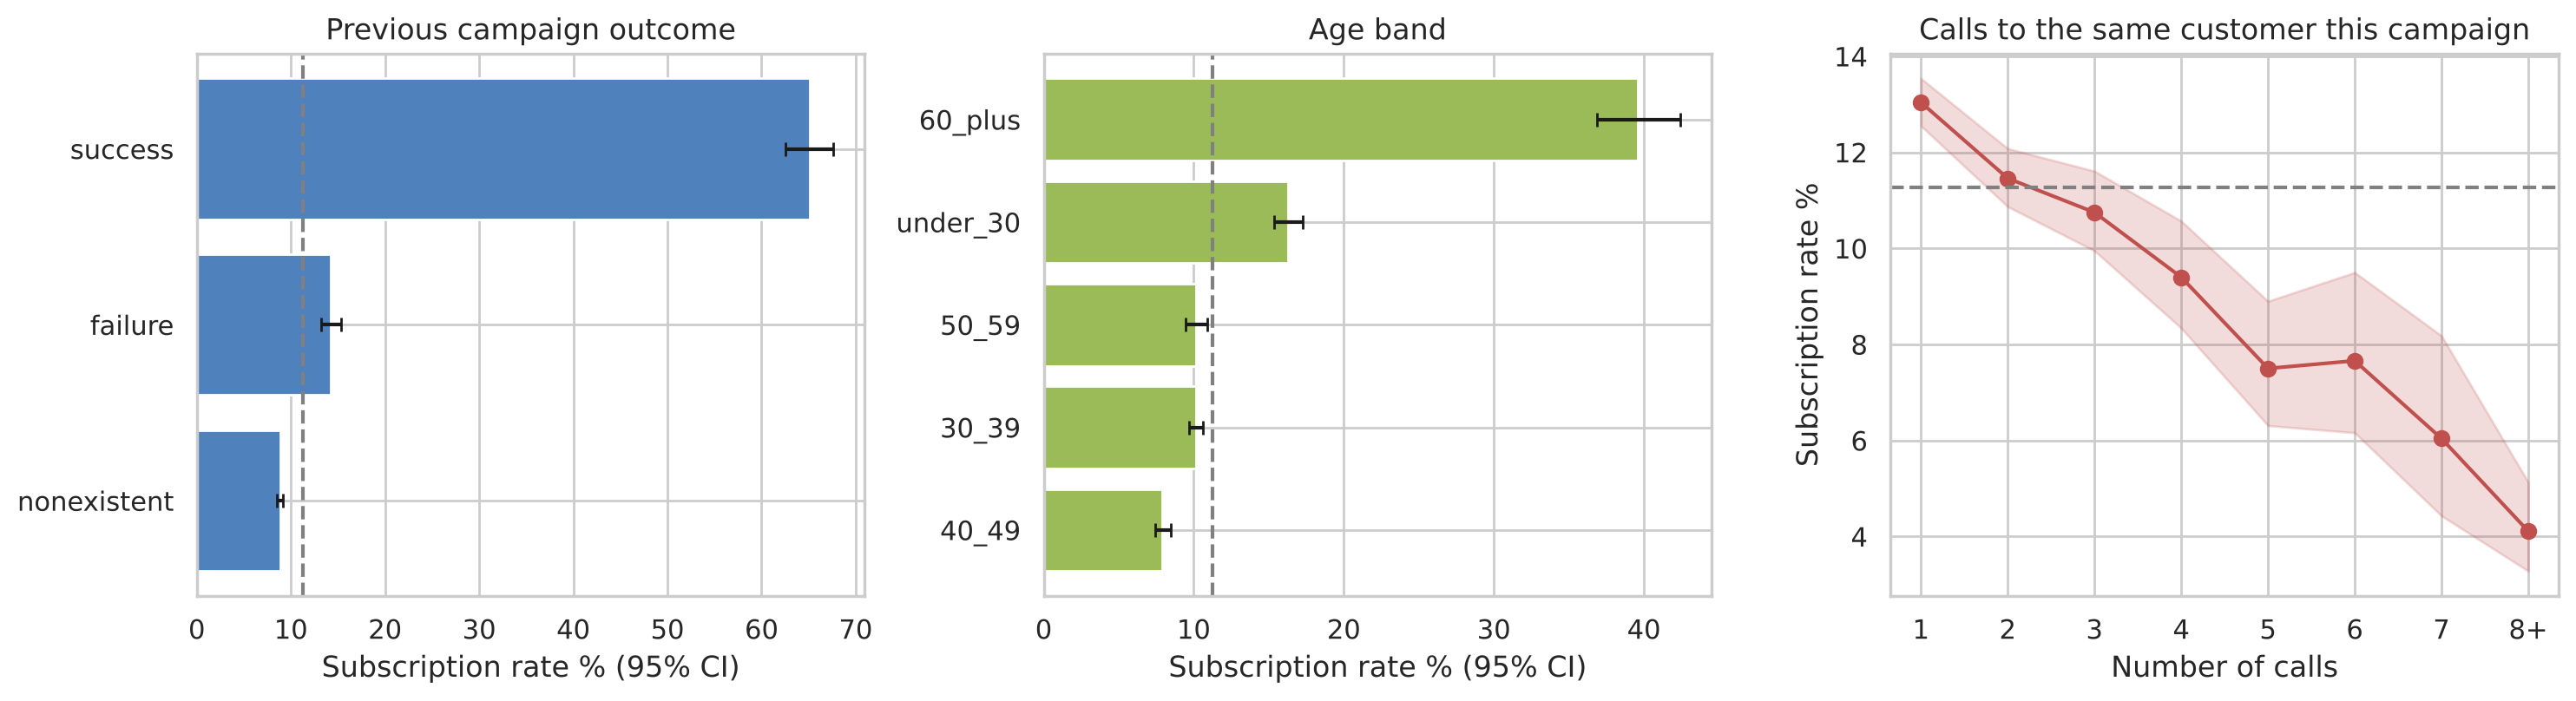

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
def bar(ax, t, title, color):
    ax.barh(t.index.astype(str), t.rate_pct, xerr=[t.rate_pct - t.ci_low_pct, t.ci_high_pct - t.rate_pct],
            color=color, capsize=3)
    ax.axvline(BASE, ls="--", c="grey"); ax.invert_yaxis()
    ax.set_title(title); ax.set_xlabel("Subscription rate % (95% CI)")
bar(axes[0], segments["poutcome"], "Previous campaign outcome", "#4f81bd")
bar(axes[1], segments["age_band"], "Age band", "#9bbb59")
axes[2].plot(call_tab.index, call_tab.rate_pct, marker="o", c="#c0504d")
axes[2].fill_between(call_tab.index, call_tab.ci_low_pct, call_tab.ci_high_pct, alpha=.2, color="#c0504d")
axes[2].axhline(BASE, ls="--", c="grey"); axes[2].set_title("Calls to the same customer this campaign")
axes[2].set_xlabel("Number of calls"); axes[2].set_ylabel("Subscription rate %")
plt.tight_layout(); plt.savefig(CONFIG["figure_dir"] / "03_decision_segments.png", dpi=150); plt.show()

In [21]:
# Priority segment: previous success OR aged 60+ OR student/retired, reached on mobile
priority = ((clean.poutcome == "success") | (clean.age >= 60) | clean.job.isin(["student", "retired"])) \
           & (clean.contact == "cellular")
seg = clean.groupby(priority).subscribed.agg(customers="size", subscribed="sum", rate="mean")
seg.index = seg.index.map({True: "priority segment", False: "everyone else"})
seg["share_of_customers_pct"] = 100 * seg.customers / len(clean)
seg["share_of_subscribers_pct"] = 100 * seg.subscribed / clean.subscribed.sum()
seg["rate"] = 100 * seg.rate
seg.round(1)

,customers,subscribed,rate,share_of_customers_pct,share_of_subscribers_pct
everyone else,38017,3290,8.7,92.3,70.9
priority segment,3159,1349,42.7,7.7,29.1


In [22]:
# Calls beyond the 3rd attempt: effort vs return
over3 = clean.campaign > 3
extra_calls = (clean.loc[over3, "campaign"] - 3).sum()
print(f"Customers called more than 3 times: {over3.sum():,} ({over3.mean():.1%})")
print(f"Calls made beyond the 3rd attempt: {extra_calls:,} ({extra_calls / clean.campaign.sum():.1%} of all calls)")
print(f"Subscription rate for customers on 4+ calls: {100*clean.loc[over3,'subscribed'].mean():.1f}% vs {BASE:.1f}% overall")
print(f"Subscriptions among customers who needed 4+ calls: {clean.loc[over3,'subscribed'].sum():,} "
      f"({clean.loc[over3,'subscribed'].sum()/clean.subscribed.sum():.1%} of all subscriptions)")

Customers called more than 3 times: 7,634 (18.5%)
Calls made beyond the 3rd attempt: 28,043 (26.5% of all calls)
Subscription rate for customers on 4+ calls: 7.3% vs 11.3% overall
Subscriptions among customers who needed 4+ calls: 555 (12.0% of all subscriptions)


**Reading the results (details in the decision brief):**
- **Previous success** is the strongest signal before a call: about 65% subscribe, roughly 6× the baseline.
- **Age 60+, students and retirees** subscribe at 2–3.5× the baseline. Middle-aged groups and blue-collar workers are below it.
- **Mobile (cellular)** contacts convert at about 3× the rate of landline contacts.
- **Repeated calling has diminishing returns.** The rate falls with every extra call, and the 4th and later calls use a large share of call time for a small share of subscriptions.
- These are associations in historical data, not proof of cause. The macroeconomic context (low Euribor rates in 2009–10) also lifted rates in some months (see Week 3).

## 8. Export artefacts

In [23]:
clean.to_csv(CONFIG["clean_file"], index=False)
raw_profile.to_csv(CONFIG["output_dir"] / "data_quality_report_raw.csv")
quality_profile(clean).to_csv(CONFIG["output_dir"] / "data_quality_report_clean.csv")
validation.to_csv(CONFIG["output_dir"] / "validation_checks.csv", index=False)
before_after.to_csv(CONFIG["output_dir"] / "before_after_summary.csv", index=False)
pd.concat({k: v for k, v in segments.items()}, names=["dimension", "segment"]).to_csv(
    CONFIG["output_dir"] / "segment_subscription_rates.csv")
call_tab.to_csv(CONFIG["output_dir"] / "subscription_by_call_count.csv")

# Round-trip check: re-read the exported file
reloaded = pd.read_csv(CONFIG["clean_file"])
assert reloaded.shape == clean.shape
print("Exported", CONFIG["clean_file"].relative_to(ROOT), reloaded.shape)
for p in sorted(CONFIG["output_dir"].rglob("*.*")):
    print(" -", p.relative_to(ROOT))

Exported data/processed/bank_marketing_clean.csv (41176, 26)
 - outputs/before_after_summary.csv
 - outputs/data_quality_report_clean.csv
 - outputs/data_quality_report_raw.csv
 - outputs/figures/01_unknown_values.png
 - outputs/figures/02_ranges_and_sentinels.png
 - outputs/figures/03_decision_segments.png
 - outputs/segment_subscription_rates.csv
 - outputs/subscription_by_call_count.csv
 - outputs/validation_checks.csv


## 9. Assumptions and limitations

**Assumptions**
1. The 12 exact duplicates are data-entry repeats, not separate customers (there is no customer ID to confirm this).
2. `"unknown"` means the bank didn't record the value. It is treated as a valid category, not imputed.
3. `pdays = 999` means *no known days since last contact*. Where it conflicts with `previous > 0`, `previous` is trusted.
4. High call counts (up to 56) are real operational records, not errors.
5. Each row is one call record for one customer in a campaign. UCI doesn't say whether the same person appears in several campaigns.

**Limitations**
1. **One bank, one country, 2008–2010.** Results may not carry over to today's rates, channels or customers.
2. **No year column.** The financial crisis and falling interest rates are mixed into month effects.
3. **Observational data.** Segment differences are associations. For example, previous-success customers may be more financially engaged in general, and calling them doesn't *cause* subscription.
4. **Class imbalance:** only 11.3% subscribed, so small segments have wide confidence intervals.
5. **`duration` excluded** from decision analysis because of leakage. Any model built later must also exclude it.
6. **No cost or revenue data**, so recommendations are about conversion rate and call effort, not profit.
7. 20.9% of `credit_default` is unknown and it has only 3 "yes", so it has little use for decisions.